# Práctica 2: Autoencoders
## Parte I — Eliminación de ruido (*Denoising Autoencoder*)

### Objetivo

El objetivo de esta sección es desarrollar un **autoencoder convolucional** que pueda eliminar eficazmente el ruido gaussiano de las imágenes del manuscrito digitalizadas en el conjunto de datos **MNIST**.

Para lograr esto, una red neuronal está entrenada para tomar imágenes ruidosas como entrada y aprender a reconstruir sus versiones limpias.

El procedimiento se divide en cuatro etapas:

1. **La preparación de datos** implica cargar el conjunto de datos del MNIST y estandarizar las imágenes.
2. **La generación de ruido** implica añadir perturbaciones gaussianas a las imágenes.
3. **Entrenamiento**: aprender a reconstruir a través de un autocodificador.
4. **Evaluación**: Comparación visual y cuantitativa de las imágenes ruidosas y reconstruidas.

La calidad de reconstrucción se evaluará utilizando el **error cuadrado medio (MSE)**, una métrica que cuantifica la diferencia entre los valores de píxeles y los de la imagen reconstruida.


##1. Conectar Google Drive y crear las carpetas

Primero, vinculamos Google Colab a Google Drive para garantizar el almacenamiento persistente.

Se crea una carpeta principal llamada `Practice2_Autoencoders`, que se organiza en tres subdirectorios.

| Carpeta | Función |
|---|---|
El directorio `datos/` se utiliza para almacenar el conjunto de datos del MNIST.
Guarde los pesos de autoencoder entrenados en el directorio `modelos/`.
El directorio `resultados/` se utiliza para almacenar gráficos, reconstrucciones y métricas.

Esta organización le permite retener los resultados después de que una sesión Colab concluye, racionalizando su análisis y entrega posteriores.


In [2]:
from google.colab import drive
from pathlib import Path

drive.mount('/content/drive')

PROJECT_DIR = Path('/content/drive/MyDrive/Practica2_Autoencoders')

DATA_DIR = PROJECT_DIR / 'data'
MODELS_DIR = PROJECT_DIR / 'models'
RESULTS_DIR = PROJECT_DIR / 'results'

for folder in [DATA_DIR, MODELS_DIR, RESULTS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Google Drive conectado correctamente.")
print("Carpeta del proyecto:", PROJECT_DIR)


Mounted at /content/drive
Google Drive conectado correctamente.
Carpeta del proyecto: /content/drive/MyDrive/Practica2_Autoencoders


##2. Importar librerías y configurar GPU


Las bibliotecas necesarias para desarrollar y evaluar el autoencoder son importadas.

- **PyTorch**: Construir, entrenar y evaluar la red neuronal.
- **Torchvision**: descarga y preparación del conjunto MNIST.
- **NumPy**: operaciones numéricas y configuración de la semilla.
- **Matplotlib**: representación de imágenes y gráficas.

Una **semilla aleatoria de 42**** se establece para mejorar la reproducibilidad de los experimentos.

También verifica la disponibilidad de una GPU. En nuestro caso, el entrenamiento se realiza utilizando CUDA, que acelera las operaciones de red neuronal en comparación con la ejecución en una CPU sola.

In [3]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np
import random

seed = 42

random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Dispositivo utilizado:", device)
print("Versión de PyTorch:", torch.__version__)


Dispositivo utilizado: cuda
Versión de PyTorch: 2.14.1+cu130


##3. Cargar MNIST desde Google Drive

Se utiliza el conjunto de datos del **MNIST**, que comprende imágenes en escala de grises de dígitos manuscritos que van desde 0 hasta 9.

| Característica | Valor |
|---|---|
| Imágenes de entrenamiento | 60. 000 |
| Imágenes de evaluación | 10. 000 |
| Resolución | 28 × 28 píxeles |
| Canales | 1 (escala de grises) |
| Rango de valores | [0, 1] |
El tamaño del lote está fijado en 64.

La transformación `ToTensor()` convierte las imágenes en tensores y normaliza sus valores al intervalo **[0, 1]**.

Los datos se organizan utilizando el sistema " DataLoader ", que facilita el procesamiento por lotes durante la capacitación y la evaluación.

En este experimento, las 10. 000 imágenes del conjunto de pruebas MNIST se emplean como un conjunto de validación para analizar el comportamiento del modelo.




In [4]:
transform = transforms.ToTensor()

mnist_data = datasets.MNIST(
    root=str(DATA_DIR),
    train=True,
    download=True,
    transform=transform
)

data_loader = torch.utils.data.DataLoader(
    dataset=mnist_data,
    batch_size=64,
    shuffle=True
)

mnist_data_valid = datasets.MNIST(
    root=str(DATA_DIR),
    train=False,
    download=True,
    transform=transform
)

data_loader_valid = torch.utils.data.DataLoader(
    dataset=mnist_data_valid,
    batch_size=64,
    shuffle=False
)

images, labels = next(iter(data_loader))

print("Número de imágenes de entrenamiento:", len(mnist_data))
print("Número de imágenes de validación:", len(mnist_data_valid))
print("Dimensiones del batch:", images.shape)
print("Valor mínimo:", torch.min(images))
print("Valor máximo:", torch.max(images))


100%|██████████| 9.91M/9.91M [00:00<00:00, 12.9MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 361kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.20MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 10.1MB/s]

Número de imágenes de entrenamiento: 60000
Número de imágenes de validación: 10000
Dimensiones del batch: torch.Size([64, 1, 28, 28])
Valor mínimo: tensor(0.)
Valor máximo: tensor(1.)


##4. Función para añadir ruido gaussiano

Para entrenar un autoencoder de eliminación de ruido, primero debemos generar versiones degradadas de las imágenes.

La función `add_noise()`, que añade **ruido gaussiano aleatorio** a cada píxel, se define de la siguiente manera:

$$
\widetilde{x} = \operatorname{clip}(x + \varepsilon, 0, 1)
$$

donde:

- $x$ representa la imagen ruidosa.
- $\widetilde{x}$ representa la imagen con ruido.
- $\varepsilon \sim \mathcal{N}(0,\sigma^2)$ representa el ruido gaussiano.
- El factor ruido utilizado es $\sigma = 0. 3$.

La función `torch.clamp()' restringe los valores resultantes al rango **[0, 1]**, evitando así que las intensidades caigan fuera del espectro válido.

**Objetivo**: generar imágenes suficientemente degradadas para que la red aprenda a recuperar su contenido.





In [5]:
def add_noise(images, noise_factor=0.3):
    noise = torch.randn_like(images) * noise_factor

    noisy_images = images + noise

    noisy_images = torch.clamp(
        noisy_images,
        min=0.0,
        max=1.0
    )

    return noisy_images


##5. Visualizar imágenes originales y con ruido

Antes de entrenar, se muestran ejemplos del MNIST para evaluar el impacto del ruido gaussiano.

Se representan dos filas:

- **Fila superior**: imágenes originales sin alteraciones.
- **Fila inferior**: las mismas imágenes después de añadir ruido gaussiano.

Esta comparación nos permite observar cómo el ruido altera las intensidades de los píxeles, ocultando así ciertos rastros de dígitos.

La figura se guarda automáticamente como `original_vs_noisy`. Png` para capturar el estado de imagen inicial antes de aplicar el autoencoder.


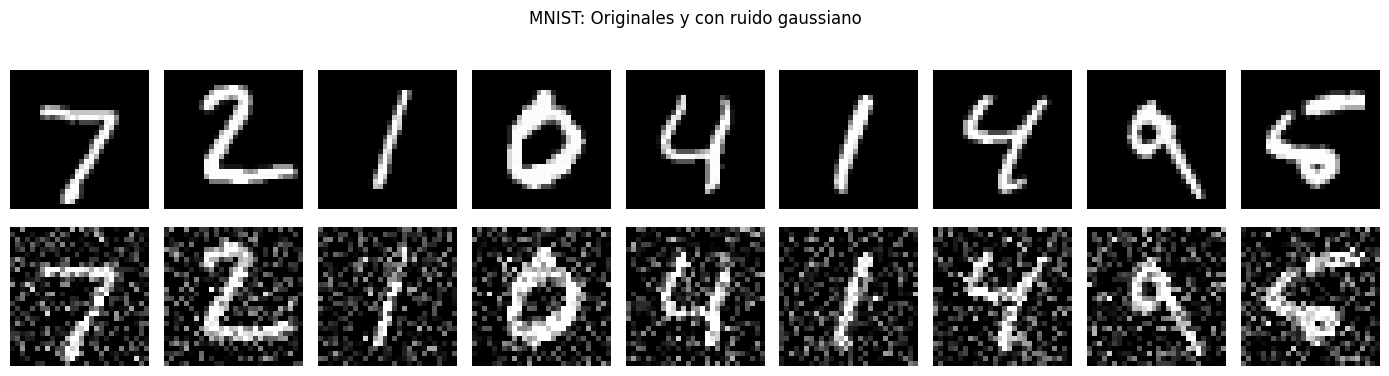

In [6]:
images, labels = next(iter(data_loader_valid))

noisy_images = add_noise(images, noise_factor=0.3)

plt.figure(figsize=(14, 4))

for i in range(9):

    plt.subplot(2, 9, i + 1)
    plt.imshow(images[i][0], cmap='gray', vmin=0, vmax=1)
    plt.axis('off')

    plt.subplot(2, 9, i + 10)
    plt.imshow(noisy_images[i][0], cmap='gray', vmin=0, vmax=1)
    plt.axis('off')

plt.suptitle("MNIST: Originales y con ruido gaussiano")
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "original_vs_noisy.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()


##6. Definir el autoencoder convolucional

Un **auto-encoder** se implementa usando una arquitectura revolucionaria derivada de la clase proporcionada.

El modelo se divide en dos componentes:

**Encoder (codificador)**

Gradualmente, reduce las dimensiones espaciales de la imagen y saca características clave usando capas convolucionales y activaciones ReLU.

**Decoder (decodificador)**

Reconstruye la imagen a partir de su representación comprimida utilizando convoluciones transpuestas.

El recorrido de las dimensiones es:

| Etapa | Dimensiones |
|---|---|
La imagen de entrada tiene dimensiones de 1 × 28 × 28.
La primera capa convolucional tiene dimensiones de 16 × 14 × 14.
La segunda capa convolucional tiene dimensiones de 32 × 7 × 7.
La representación latente tiene dimensiones de 64 × 1 × 1.
La primera capa de convolución transpuesta tiene dimensiones de 32 × 7 × 7.
La segunda capa de convolución transpuesta tiene un tamaño de salida de 16 × 14 × 14.
La imagen reconstruida tiene dimensiones de 1 × 28 × 28.

La capa final emplea una función de activación **sigmoide** para limitar los valores de píxeles reconstruidos dentro del rango de 0 a 1.

El objetivo del modelo es aprender una función:

$$
\hat{x}=D(E(\widetilde{x}))
$$

Donde $E$ denota el codificador, $D$ denota el decodificador, $\widetilde{x}$ representa la imagen ruidosa y $\hat{x}$ representa la imagen reconstruida.

Durante el entrenamiento, el modelo aprende a preservar las características de dígitos relevantes y minimiza las perturbaciones introducidas.



In [7]:
class Autoencoder(nn.Module):

    def __init__(self):
        super().__init__()

        self.encoder = nn.Sequential(

            nn.Conv2d(
                1, 16, 3,
                stride=2,
                padding=1
            ),
            nn.ReLU(),

            nn.Conv2d(
                16, 32, 3,
                stride=2,
                padding=1
            ),
            nn.ReLU(),

            nn.Conv2d(
                32, 64, 7
            )
        )

        self.decoder = nn.Sequential(

            nn.ConvTranspose2d(
                64, 32, 7
            ),
            nn.ReLU(),

            nn.ConvTranspose2d(
                32, 16, 3,
                stride=2,
                padding=1,
                output_padding=1
            ),
            nn.ReLU(),

            nn.ConvTranspose2d(
                16, 1, 3,
                stride=2,
                padding=1,
                output_padding=1
            ),
            nn.Sigmoid()
        )

    def forward(self, x):

        encoded = self.encoder(x)
        decoded = self.decoder(encoded)

        return decoded


model = Autoencoder().to(device)

print(model)


Autoencoder(
  (encoder): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(16, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (3): ReLU()
    (4): Conv2d(32, 64, kernel_size=(7, 7), stride=(1, 1))
  )
  (decoder): Sequential(
    (0): ConvTranspose2d(64, 32, kernel_size=(7, 7), stride=(1, 1))
    (1): ReLU()
    (2): ConvTranspose2d(32, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), output_padding=(1, 1))
    (3): ReLU()
    (4): ConvTranspose2d(16, 1, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), output_padding=(1, 1))
    (5): Sigmoid()
  )
)


##7. Configurar entrenamiento

Se han definido los hiperparametros necesarios para entrenar el autoencoder.

| Parámetro | Valor |
|---|---|
| Función de pérdida | MSELoss |
| Optimizador | Adam |
| Tasa de aprendizaje | 0. 001 |
| Regularización (weight decay) | 0. 00001 |
| Número de épocas | 20 |
| Factor de ruido | 0. 3 |
| Tamaño de lote | 64 |

El **error cuadrado medio (MSE)** sirve como la función de pérdida.

$$
MSE=\frac{1}{N}\sum_{i=1}^{N}(x_i-\hat{x}_i)^2
$$

Donde $x_i$ denota el valor del píxel y \hat{x}_i$ su contraparte reconstruida.

El optimizador **Adam** ajusta los parámetros de la red para minimizar esta discrepancia.

**Importante**: Aunque la entrada del modelo contiene ruido, la **imagen original sin ruido** es siempre la versión libre de ruido. Por lo tanto, el autoencoder aprende a filtrar las perturbaciones en lugar de replicarlas.



In [8]:
criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-3,
    weight_decay=1e-5
)

num_epochs = 20
noise_factor = 0.3

train_losses = []
valid_losses = []

print("Épocas:", num_epochs)
print("Nivel de ruido:", noise_factor)


Épocas: 20
Nivel de ruido: 0.3


##8. Entrenar el Denoising Autoencoder

El autoencoder se entrena **20 épocas** usando imágenes MNIST a las que se ha añadido el ruido gaussiano.

El siguiente procedimiento se ejecuta para cada lote de entrenamiento.

1. Se obtiene un conjunto de imágenes originales.
2. Se genera una versión ruidosa de esas imágenes.
3. El autoencoder toma imágenes ruidosas como entrada y genera sus reconstrucciones.
4. El MSE se calcula utilizando las imágenes.
5. Los pesos de red se actualizan utilizando el optimizador Adam y la retropropagación.

Al final de cada época, la pérdida también se calcula en el conjunto de validación sin actualizar los parámetros del modelo.

Para garantizar comparaciones consistentes entre diferentes períodos, se utiliza un conjunto fijo de imágenes ruidosas durante la fase de validación.

###Resultados obtenidos:

| Métrica | Época 1 | Época 20 |
|---|---:|---:|
| MSE entrenamiento | 0.03484 | 0.00609 |
| MSE validación | 0.01238 | 0.00599 |

La reducción significativa de la pérdida durante el entrenamiento sugiere que el modelo está aprendiendo progresivamente a reconstruir las imágenes.

Además, los valores de entrenamiento y validación final son muy cercanos, sin indicación clara de sobreajuste en las curvas observadas.



In [9]:
torch.manual_seed(seed)

valid_noisy = add_noise(
    mnist_data_valid.data.unsqueeze(1).float() / 255.0,
    noise_factor=noise_factor
)

for epoch in range(num_epochs):

    model.train()
    running_loss = 0.0

    for img, _ in data_loader:

        img = img.to(device)

        noisy_img = add_noise(
            img,
            noise_factor=noise_factor
        )

        recon = model(noisy_img)

        loss = criterion(recon, img)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * img.size(0)

    train_loss = running_loss / len(data_loader.dataset)
    train_losses.append(train_loss)

    model.eval()
    running_valid_loss = 0.0

    with torch.no_grad():

        for batch_idx, (img, _) in enumerate(data_loader_valid):

            img = img.to(device)

            start = batch_idx * data_loader_valid.batch_size
            end = start + img.size(0)

            noisy_img = valid_noisy[start:end].to(device)

            recon = model(noisy_img)

            loss = criterion(recon, img)

            running_valid_loss += loss.item() * img.size(0)

    valid_loss = running_valid_loss / len(data_loader_valid.dataset)
    valid_losses.append(valid_loss)

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {train_loss:.5f} "
        f"Valid Loss: {valid_loss:.5f}"
    )

print("Entrenamiento finalizado.")


Epoch [1/20] Train Loss: 0.03484 Valid Loss: 0.01238
Epoch [2/20] Train Loss: 0.01059 Valid Loss: 0.00892
Epoch [3/20] Train Loss: 0.00837 Valid Loss: 0.00773
Epoch [4/20] Train Loss: 0.00744 Valid Loss: 0.00700
Epoch [5/20] Train Loss: 0.00701 Valid Loss: 0.00665
Epoch [6/20] Train Loss: 0.00673 Valid Loss: 0.00664
Epoch [7/20] Train Loss: 0.00657 Valid Loss: 0.00644
Epoch [8/20] Train Loss: 0.00646 Valid Loss: 0.00627
Epoch [9/20] Train Loss: 0.00639 Valid Loss: 0.00623
Epoch [10/20] Train Loss: 0.00634 Valid Loss: 0.00620
Epoch [11/20] Train Loss: 0.00630 Valid Loss: 0.00617
Epoch [12/20] Train Loss: 0.00627 Valid Loss: 0.00615
Epoch [13/20] Train Loss: 0.00623 Valid Loss: 0.00609
Epoch [14/20] Train Loss: 0.00618 Valid Loss: 0.00611
Epoch [15/20] Train Loss: 0.00617 Valid Loss: 0.00611
Epoch [16/20] Train Loss: 0.00615 Valid Loss: 0.00608
Epoch [17/20] Train Loss: 0.00613 Valid Loss: 0.00608
Epoch [18/20] Train Loss: 0.00611 Valid Loss: 0.00603
Epoch [19/20] Train Loss: 0.00609 Val

##9. Gráfica de entrenamiento y *validación*

La representación gráfica ilustra la evolución del Error **Mean Squared (MSE) para entrenamiento y validación** se establece a través de 20 épocas.

La gráfica permite estudiar tres aspectos fundamentales:

- **Convergencia**: comprobar si el error disminuye progresivamente.
- **Estabilidad**: observar si el entrenamiento presenta oscilaciones importantes.
- **Generalización**: Comparar las pérdidas de entrenamiento y validación para identificar posibles signos de sobreajuste.

Interpretación de los resultados

En las primeras etapas, se produce una reducción significativa del error, especialmente dentro del conjunto de actividades de formación.

A continuación, las curvas se estabilizan alrededor de un MSE de **0.006**, lo que indica que el modelo presenta un comportamiento relativamente estable.

La alineación cercana de las dos curvas indica que el autoencoder se generaliza efectivamente a las imágenes de validación.

La gráfica se almacena en `training_validation_loss. png`.





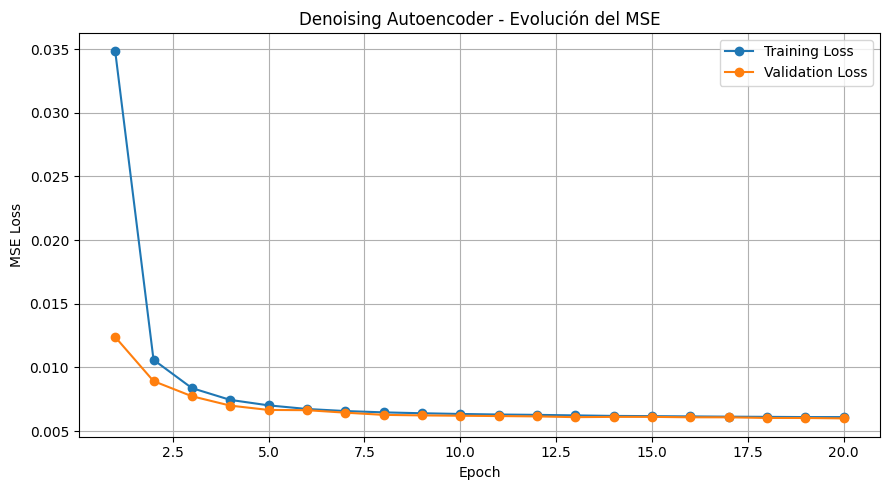

In [10]:
plt.figure(figsize=(9, 5))

plt.plot(
    range(1, num_epochs + 1),
    train_losses,
    label="Training Loss",
    marker='o'
)

plt.plot(
    range(1, num_epochs + 1),
    valid_losses,
    label="Validation Loss",
    marker='o'
)

plt.title("Denoising Autoencoder - Evolución del MSE")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "training_validation_loss.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()


## 10. Resultados finales: matriz de 3×9 imágenes

Una vez entrenado el modelo, se realiza una comparación visual entre las imágenes, las imágenes degradadas y las reconstrucciones resultantes.

Se utiliza una matriz **3x9**.

| Fila | Contenido |
|---|---|
| 1 | Imágenes originales de MNIST |
| 2 | Imágenes con ruido gaussiano |
| 3 |  Imágenes reconstruidas por el autoencoder. |

Análisis de los resultados

Las imágenes que contienen ruido muestran distorsiones visibles tanto en el fondo como en los trazos de dígitos.

Tras la aplicación del autoencoder, se observa una **notable disminución del ruido**, lo que resulta en formas recuperadas que se asemejan mucho a los originales.

Aunque ciertos contornos parecen algo lisos, los dígitos conservan sus características primarias y permanecen fácilmente identificables.

Estos resultados ofrecen una evaluación **cualitativa** de la capacidad del modelo para reconstruir datos.

La figura se guarda como `denoising_results. png`.




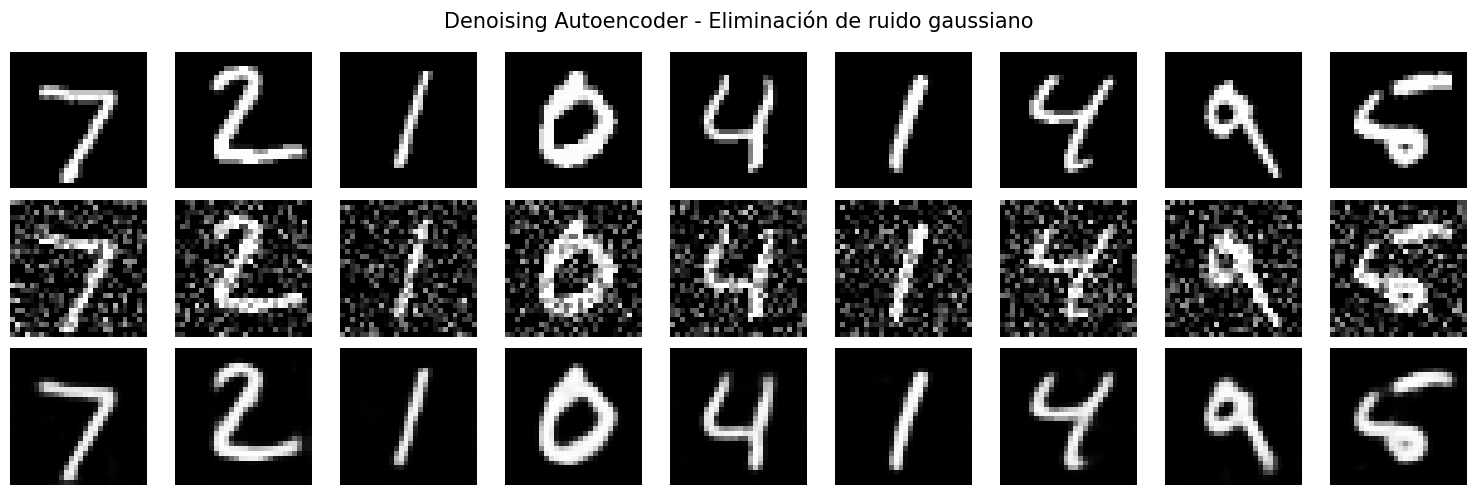

In [11]:
model.eval()

images = torch.stack([
    mnist_data_valid[i][0]
    for i in range(9)
]).to(device)

noisy_images = valid_noisy[:9].to(device)

with torch.no_grad():
    reconstructed_images = model(noisy_images)

images = images.cpu()
noisy_images = noisy_images.cpu()
reconstructed_images = reconstructed_images.cpu()

n = 9

fig, axes = plt.subplots(
    3, n,
    figsize=(15, 5)
)

row_labels = [
    "Original",
    "Con ruido",
    "Reconstruida"
]

for i in range(n):

    axes[0, i].imshow(
        images[i, 0],
        cmap='gray',
        vmin=0,
        vmax=1
    )

    axes[1, i].imshow(
        noisy_images[i, 0],
        cmap='gray',
        vmin=0,
        vmax=1
    )

    axes[2, i].imshow(
        reconstructed_images[i, 0],
        cmap='gray',
        vmin=0,
        vmax=1
    )

    for row in range(3):
        axes[row, i].axis('off')

for row, label in enumerate(row_labels):
    axes[row, 0].set_ylabel(
        label,
        fontsize=12,
        rotation=90,
        labelpad=15
    )

plt.suptitle(
    "Denoising Autoencoder - Eliminación de ruido gaussiano",
    fontsize=15
)

plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "denoising_results.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()


## 11. Evaluar la reducción del error

Para evaluar objetivamente el rendimiento del autoencoder, el **error cuadrado medio (MSE)** se calcula en las 10. 000 imágenes dentro del conjunto de validación.

Se comparan dos situaciones:

1. **MSE con ruido**: la diferencia entre las imágenes y sus contrapartes ruidosas.
2. **La reconstrucción del MSE** se refiere a la diferencia entre las imágenes y las reconstruidas por el autoencoder.

Resultados experimentales

| Métrica | Valor |
|---|---:|
| MSE con ruido | 0. 046614 |
| MSE de reconstrucción | 0. 005993 |
| **El MES se redujo en** | **87,14%.** |

La reducción porcentual se calcula mediante:

$$
\text{Reducción del MSE}=
\frac{MSE_{\text{ruido}}-MSE_{\text{reconstrucción}}}
{MSE_{\text{ruido}}}\times100
$$

Sustituyendo los resultados:

$$
\frac{0.046614-0.005993}{0.046614}\times100
\approx 87.14\%
$$


Interpretación

El autoencoder logra una reducción de aproximadamente **87.14%** en el error cuadrático medio en comparación con las imágenes sonoras.

Esto indica que las imágenes reconstruidas están significativamente más cerca de los originales que las versiones degradadas.

Los hallazgos cuantitativos se alinean con las reconstrucciones presentadas en la sección anterior, lo que valida la eficacia del modelo para esta tarea específica.

In [12]:
model.eval()

total_noisy_error = 0.0
total_recon_error = 0.0
total_pixels = 0

with torch.no_grad():

    for batch_idx, (img, _) in enumerate(data_loader_valid):

        img = img.to(device)

        start = batch_idx * data_loader_valid.batch_size
        end = start + img.size(0)

        noisy_img = valid_noisy[start:end].to(device)

        recon = model(noisy_img)

        total_noisy_error += F.mse_loss(
            noisy_img, img, reduction='sum'
        ).item()

        total_recon_error += F.mse_loss(
            recon, img, reduction='sum'
        ).item()

        total_pixels += img.numel()

mse_noisy = total_noisy_error / total_pixels
mse_reconstructed = total_recon_error / total_pixels

improvement = (
    (mse_noisy - mse_reconstructed) / mse_noisy
) * 100

print(f"MSE con ruido: {mse_noisy:.6f}")
print(f"MSE reconstrucción: {mse_reconstructed:.6f}")
print(f"Reducción del MSE: {improvement:.2f}%")


MSE con ruido: 0.046614
MSE reconstrucción: 0.005993
Reducción del MSE: 87.14%


##Guardar el modelo entrenado

Una vez que el entrenamiento ha terminado y su rendimiento se verifica, los parámetros aprendidos se guardan usando `torcha. `salvar()`.

El modelo se almacena en Google Drive bajo el nombre:

`models/denoising_autoencoder. pth`

Este archivo almacena los pesos de la capa del autoencoder, permitiendo la recuperación del modelo sin necesidad de repetir las 20 carreras de entrenamiento.

Para usarlo más tarde, necesitará volver a crear la arquitectura autoencoder y cargar sus parámetros usando `load_state_dict()`.

Este enfoque facilita la **reutilización y reproducibilidad** del experimento.

In [13]:
model_path = MODELS_DIR / "denoising_autoencoder.pth"

torch.save(
    model.state_dict(),
    model_path
)

print("Modelo guardado correctamente:")
print(model_path)

Modelo guardado correctamente:
/content/drive/MyDrive/Practica2_Autoencoders/models/denoising_autoencoder.pth


##Guardar métricas en CSV

Finalmente, los resultados numéricos del experimento se guardan en archivos CSV para facilitar un análisis más detallado.

Se generan dos archivos:

| Archivo | Contenido |
|---|---|
|`training_history.csv` | Archivo CSV que contiene las métricas de entrenamiento y validación MSE para cada una de las 20 eras. |
| `denoising_metrics.csv`  | El archivo CSV contiene el factor ruido, el número de iteraciones, la media inicial de error cuadrado (MSE), los resultados de reconstrucción y la reducción porcentual en MSE. |

Ambos archivos se almacenan en el directorio `results/` de Google Drive.

Esta función de exportación le permite guardar valores experimentales, crear nuevas representaciones gráficas y comparar el rendimiento del modelo en diferentes configuraciones.



In [14]:
import pandas as pd

history = pd.DataFrame({
    "epoch": range(1, num_epochs + 1),
    "train_loss": train_losses,
    "valid_loss": valid_losses
})

history.to_csv(
    RESULTS_DIR / "training_history.csv",
    index=False
)

metrics = pd.DataFrame([{
    "noise_factor": noise_factor,
    "epochs": num_epochs,
    "mse_noisy": mse_noisy,
    "mse_reconstructed": mse_reconstructed,
    "improvement_percent": improvement
}])

metrics.to_csv(
    RESULTS_DIR / "denoising_metrics.csv",
    index=False
)

print("Resultados CSV guardados correctamente.")



Resultados CSV guardados correctamente.
